## Task 1: Load data, encode, split

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
from lime.lime_tabular import LimeTabularExplainer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

import warnings
warnings.filterwarnings("ignore")

c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df = pd.read_csv("german_credit_data.csv")
print(df.shape)
df.head()

(1000, 21)


,status_account,month_duration,credit_history,purpose,credit_amount,status_savings,years_employment,payment_to_income_ratio,status_and_sex,secondary_obligor,...,collateral,age,other_installment_plans,housing,n_credits,job,n_guarantors,telephone,is_foreign_worker,target
0,< 0 DM,6,critical account/ other credits existing (not ...,radio/television,1169,unknown/ no savings account,>= 7 years,4,male : single,none,...,none,67,none,own,2,skilled employee/ official,1,"yes, registered under the customers name",yes,good
1,0 to < 200 DM,48,existing credits paid back duly till now,radio/television,5951,< 100 DM,1 to < 4 years,2,female : divorced/separated/married,none,...,none,22,none,own,1,skilled employee/ official,1,none,yes,bad
2,no checking account,12,critical account/ other credits existing (not ...,education,2096,< 100 DM,4 to < 7 years,2,male : single,none,...,none,49,none,own,1,unskilled - resident,2,none,yes,good
3,< 0 DM,42,existing credits paid back duly till now,furniture/equipment,7882,< 100 DM,4 to < 7 years,2,male : single,guarantor,...,car,45,none,for free,1,skilled employee/ official,2,none,yes,good
4,< 0 DM,24,delay in paying off in the past,car (new),4870,< 100 DM,1 to < 4 years,3,male : single,none,...,savings agreement/life insurance,53,none,for free,2,skilled employee/ official,2,none,yes,bad


In [3]:
print(df["target"].value_counts())
y = df["target"].map({"good": 0, "bad": 1})
X = df.drop(columns="target")

cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print("Categorical columns:", cat_cols)

target
good    700
bad     300
Name: count, dtype: int64
Categorical columns: ['status_account', 'credit_history', 'purpose', 'status_savings', 'years_employment', 'status_and_sex', 'secondary_obligor', 'collateral', 'other_installment_plans', 'housing', 'job', 'telephone', 'is_foreign_worker']


In [4]:
enc = OrdinalEncoder()
X_enc = X.copy()
X_enc[cat_cols] = enc.fit_transform(X[cat_cols])

feature_names = X_enc.columns.tolist()
X_enc.head()

,status_account,month_duration,credit_history,purpose,credit_amount,status_savings,years_employment,payment_to_income_ratio,status_and_sex,secondary_obligor,residence_since,collateral,age,other_installment_plans,housing,n_credits,job,n_guarantors,telephone,is_foreign_worker
0,1.0,6,1.0,7.0,1169,4.0,3.0,4,3.0,2.0,4,1.0,67,1.0,1.0,2,1.0,1,1.0,1.0
1,0.0,48,3.0,7.0,5951,2.0,0.0,2,0.0,2.0,2,1.0,22,1.0,1.0,1,1.0,1,0.0,1.0
2,3.0,12,1.0,4.0,2096,2.0,1.0,2,3.0,2.0,3,1.0,49,1.0,1.0,1,3.0,2,0.0,1.0
3,1.0,42,3.0,5.0,7882,2.0,1.0,2,3.0,1.0,4,0.0,45,1.0,0.0,1,1.0,2,0.0,1.0
4,1.0,24,2.0,1.0,4870,2.0,0.0,3,3.0,2.0,4,3.0,53,1.0,0.0,2,1.0,2,0.0,1.0


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X_enc, y, test_size=0.2, stratify=y, random_state=42)

print("Train size:", X_train.shape)
print("Test size :", X_test.shape)

Train size: (800, 20)
Test size : (200, 20)


## Task 2: Random Forest model

In [6]:
rf = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42)
rf.fit(X_train, y_train)

pred = rf.predict(X_test)
prob = rf.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, pred)
auc = roc_auc_score(y_test, prob)

print("Model : RandomForest (200 trees, depth 8)")
print("Test accuracy :", round(acc, 2), "  ROC-AUC :", round(auc, 2))

Model : RandomForest (200 trees, depth 8)
Test accuracy : 0.76   ROC-AUC : 0.81


## Task 3: SHAP global feature importance

In [7]:
explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_test)
print(np.array(shap_values).shape)

(200, 20, 2)


In [8]:
if isinstance(shap_values, list):
    sv = shap_values[1]
else:
    sv = shap_values[:, :, 1]
print(sv.shape)

(200, 20)


In [9]:
mean_shap = np.abs(sv).mean(axis=0)
imp = pd.DataFrame({"feature": feature_names, "mean_abs_shap": mean_shap})
imp = imp.sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)

print("GLOBAL FEATURE IMPORTANCE (mean |SHAP|, class = bad)")
print("RANK  FEATURE                 MEAN|SHAP|")
print("-" * 45)
for i in range(5):
    print(f"{i+1:>3}   {imp.feature[i]:<22} {imp.mean_abs_shap[i]:.3f}")
print("-" * 45)

GLOBAL FEATURE IMPORTANCE (mean |SHAP|, class = bad)
RANK  FEATURE                 MEAN|SHAP|
---------------------------------------------
  1   status_account         0.093
  2   month_duration         0.043
  3   status_savings         0.027
  4   credit_amount          0.027
  5   collateral             0.019
---------------------------------------------


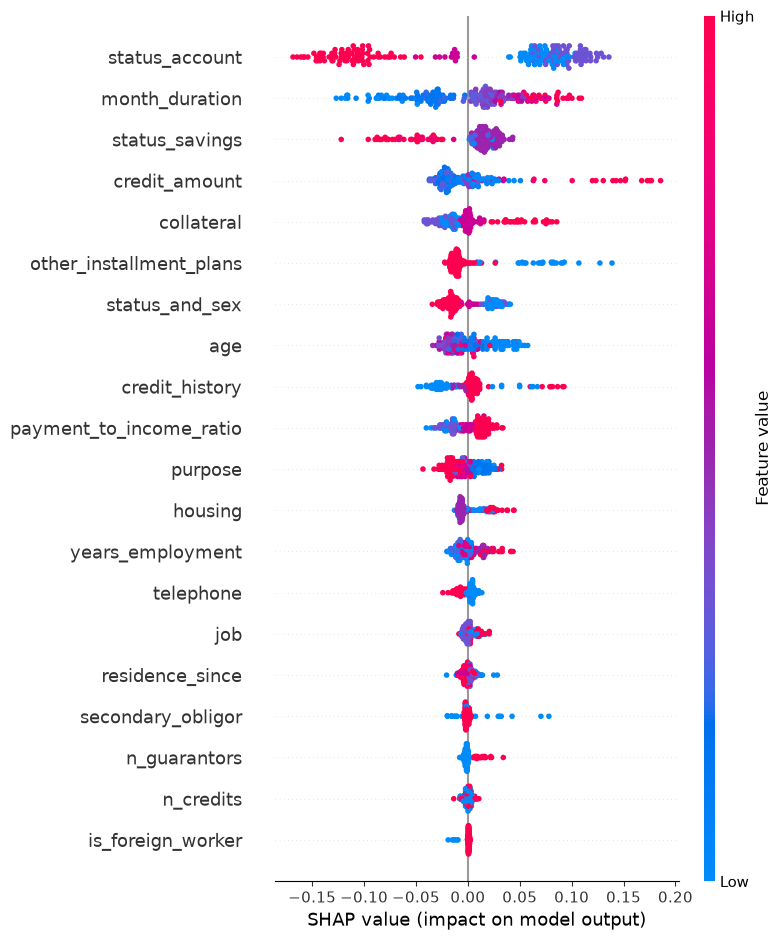

Plot saved : shap_summary.png


In [10]:
shap.summary_plot(sv, X_test, feature_names=feature_names, show=False)
plt.savefig("shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()
print("Plot saved : shap_summary.png")

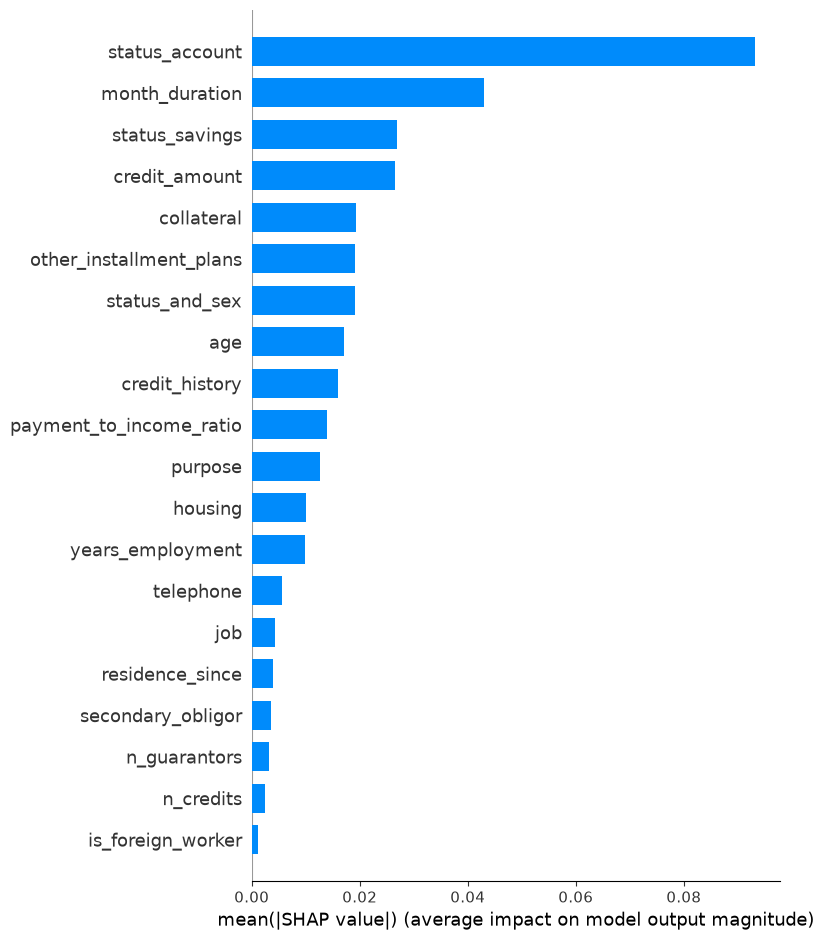

In [11]:
# bar version of the same plot (extra)
shap.summary_plot(sv, X_test, feature_names=feature_names, plot_type="bar", show=False)
plt.savefig("shap_bar.png", dpi=150, bbox_inches="tight")
plt.show()

## Task 4: SHAP waterfall plot for one rejected applicant

In [12]:
rejected = np.where(pred == 1)[0]
print("Number of rejected applicants in test set:", len(rejected))

pos = rejected[0]
row_index = X_test.index[pos]
print("Position in test set:", pos, " | original row number:", row_index)
print("P(bad) =", round(prob[pos], 2), "-> REJECTED")

Number of rejected applicants in test set: 33
Position in test set: 23  | original row number: 570
P(bad) = 0.59 -> REJECTED


In [ ]:
applicant = X.loc[row_index]
applicant

status_account                                               < 0 DM
month_duration                                                   24
credit_history             existing credits paid back duly till now
purpose                                         furniture/equipment
credit_amount                                                  3234
status_savings                                             < 100 DM
years_employment                                           < 1 year
payment_to_income_ratio                                           4
status_and_sex                  female : divorced/separated/married
secondary_obligor                                              none
residence_since                                                   4
collateral                                                     none
age                                                              23
other_installment_plans                                        none
housing                                         

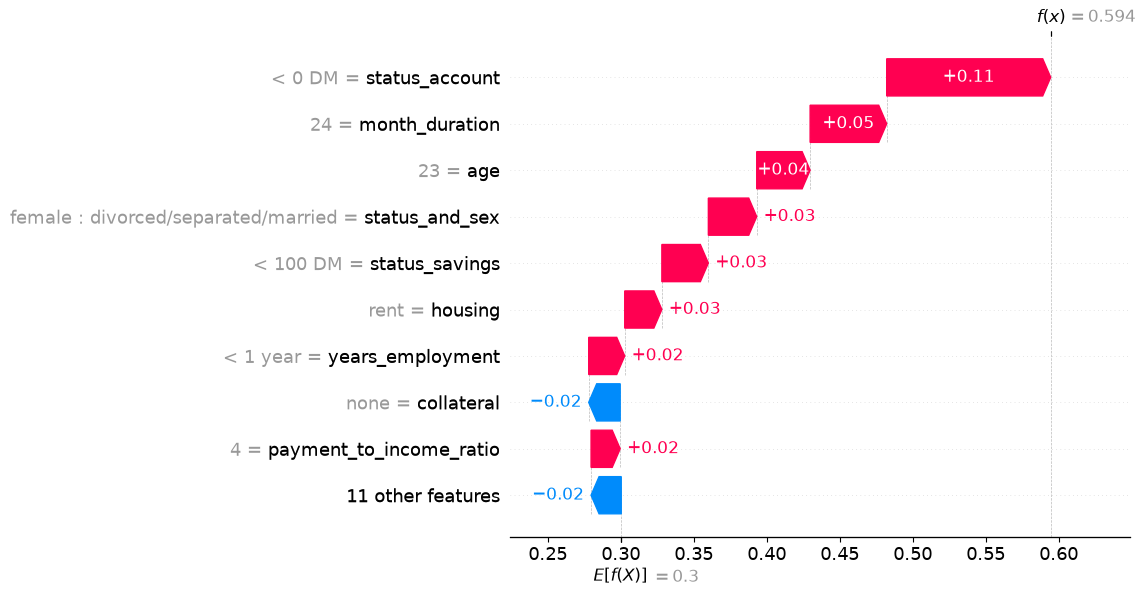

In [14]:
base = explainer.expected_value
if np.ndim(base) > 0:
    base = base[1]

exp = shap.Explanation(values=sv[pos], base_values=base,
                       data=X.loc[row_index].values, feature_names=feature_names)

shap.plots.waterfall(exp, show=False)
plt.savefig("shap_waterfall.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
shap_row = pd.Series(sv[pos], index=feature_names)
top3_shap = shap_row.sort_values(ascending=False).head(3)

print("SHAP top 3 reasons for rejection")
for f, v in top3_shap.items():
    print(f"  {f} = {X.loc[row_index, f]}   SHAP = {v:+.3f}")

SHAP top 3 reasons for rejection
  status_account = < 0 DM   SHAP = +0.112
  month_duration = 24   SHAP = +0.052
  age = 23   SHAP = +0.037


## Task 5: LIME explanation for the same applicant

In [16]:
cat_index = [feature_names.index(c) for c in cat_cols]
cat_names = {feature_names.index(c): list(enc.categories_[i]) for i, c in enumerate(cat_cols)}

lime_explainer = LimeTabularExplainer(
    X_train.values,
    feature_names=feature_names,
    class_names=["good", "bad"],
    categorical_features=cat_index,
    categorical_names=cat_names,
    mode="classification",
    random_state=42)

lime_exp = lime_explainer.explain_instance(
    X_test.iloc[pos].values, rf.predict_proba, num_features=5, labels=(1,))

print("LIME top 5 (class = bad)")
for text, w in lime_exp.as_list(label=1):
    print(f"  {text:<55} {w:+.3f}")

LIME top 5 (class = bad)
  status_account=< 0 DM                                   +0.127
  other_installment_plans=none                            -0.058
  status_and_sex=female : divorced/separated/married      +0.039
  2317.00 < credit_amount <= 3933.00                      -0.037
  age <= 27.00                                            +0.035


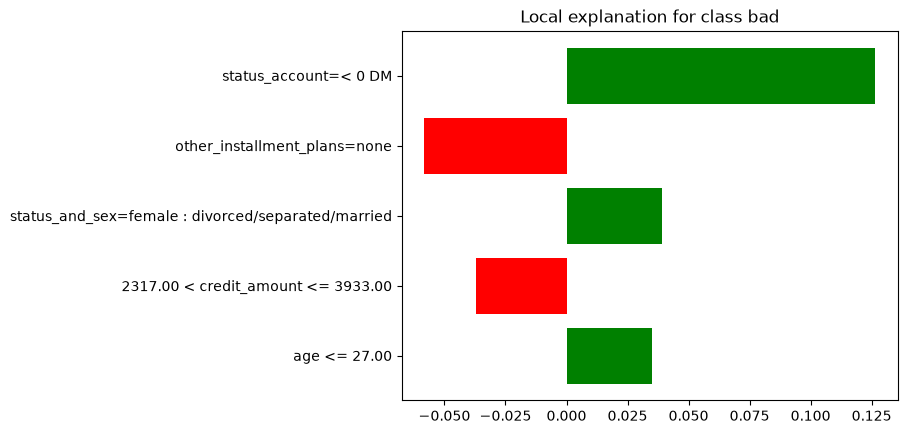

In [17]:
fig = lime_exp.as_pyplot_figure(label=1)
plt.savefig("lime_explanation.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
lime_map = lime_exp.as_map()[1]
lime_features = [feature_names[i] for i, w in lime_map]
print("LIME features:", lime_features)

shap_features = top3_shap.index.tolist()
print("SHAP features:", shap_features)

common = [f for f in shap_features if f in lime_features[:3]]
print("Common in top 3 :", common)
print("Top-3 agreement (SHAP vs LIME) :", len(common), "/ 3")

LIME features: ['status_account', 'other_installment_plans', 'status_and_sex', 'credit_amount', 'age']
SHAP features: ['status_account', 'month_duration', 'age']
Common in top 3 : ['status_account']
Top-3 agreement (SHAP vs LIME) : 1 / 3


In [19]:
print("SHAP (top 3)                        LIME (top 5)")
print("-" * 70)
shap_lines = [f"{f}={X.loc[row_index, f]}  {v:+.2f}" for f, v in top3_shap.items()]
lime_lines = [f"{t}  {w:+.2f}" for t, w in lime_exp.as_list(label=1)]
for i in range(5):
    left = shap_lines[i] if i < 3 else ""
    print(f"{left[:36]:<37} {lime_lines[i]}")

SHAP (top 3)                        LIME (top 5)
----------------------------------------------------------------------
status_account=< 0 DM  +0.11          status_account=< 0 DM  +0.13
month_duration=24  +0.05              other_installment_plans=none  -0.06
age=23  +0.04                         status_and_sex=female : divorced/separated/married  +0.04
                                      2317.00 < credit_amount <= 3933.00  -0.04
                                      age <= 27.00  +0.03


## Task 6: Rejection message and sensitive attribute check

In [20]:
sensitive = ["age", "status_and_sex", "is_foreign_worker"]

all_reasons = set(shap_features) | set(lime_features)
found = [f for f in sensitive if f in all_reasons]
print("Sensitive attributes in reasons:", found if found else "None")
if found:
    print("-> REVIEW")

Sensitive attributes in reasons: ['age', 'status_and_sex']
-> REVIEW


In [21]:
legit = [f for f in shap_features if f not in sensitive]
print("Legitimate reasons:", legit)
for f in legit:
    print(f, "=", X.loc[row_index, f])

Legitimate reasons: ['status_account', 'month_duration']
status_account = < 0 DM
month_duration = 24


In [22]:
sentence = {
    "status_account": "your current account balance is negative" if X.loc[row_index, "status_account"] == "< 0 DM" else "your current account balance is " + str(X.loc[row_index, "status_account"]),
    "month_duration": "the requested duration (" + str(X.loc[row_index, "month_duration"]) + " months) is long",
    "credit_amount": "the requested credit amount (" + str(X.loc[row_index, "credit_amount"]) + ") is high",
    "credit_history": "your past credit history shows a risk",
    "status_savings": "your savings balance is low",
    "purpose": "of the purpose of the loan",
    "years_employment": "your length of employment is short",
    "collateral": "the property/collateral you offered is limited",
    "payment_to_income_ratio": "the instalment is high compared to your income",
    "other_installment_plans": "you already have other instalment plans",
    "housing": "of your housing situation",
    "job": "of your job category",
}

parts = [sentence.get(f, f) for f in legit[:2]]
message = "Your EMI request was not approved mainly because " + " and ".join(parts) + "."
print("Message (legitimate reasons only):")
print(message)

Message (legitimate reasons only):
Your EMI request was not approved mainly because your current account balance is negative and the requested duration (24 months) is long.
